# Volcanes que pintan rayas en las nubes

Un volcán en medio del océano suelta dióxido de azufre (SO₂) y, horas después, una franja de nubes se ve más blanca que las de alrededor. ¿Cuánto de ese brillo lo pone la química que convierte el gas en partículas?

**Paper:** Christensen et al. (2026), *Chemical processing of sulfur dioxide enhances cloud sensitivity to aerosols*, Nature Geoscience. [DOI: 10.1038/s41561-026-02140-9](https://doi.org/10.1038/s41561-026-02140-9)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ciencia-a-Mordiscos/lab/blob/main/papers/2026-11-27-dioxido-azufre-brillo-nubes/notebook.ipynb)

**Video:** pendiente

## Qué midieron

El equipo siguió las nubes que cruzan las plumas de cuatro volcanes en islas remotas (Kīlauea, Ambrym, Yasur y Mt. Michael) y de dos fuentes industriales (la refinería de Come By Chance y el complejo de níquel de Norilsk). En imágenes del satélite Aqua (sensor MODIS) de 2015 a 2017 marcaron a mano 281 estelas de contaminación (*pollution tracks*): franjas de nube más brillante que nacen en la fuente.

Luego compararon esas nubes con un modelo climático global (CAM6) corrido dos veces: con la química que oxida el SO₂ y lo convierte en partículas de sulfato, y sin ella. La diferencia entre las dos corridas es lo que esa química le añade al brillo de la nube.

In [1]:
# ══════════════════════════════════════════════════════════════
# Configuración — modifica estos valores para explorar
# ══════════════════════════════════════════════════════════════
VARIABLE_KIL = 'ccn_01'      # Variable de Kīlauea en CAM6: 'ccn_01', 'nd', 'so4', 'lwp', 'albedo_nube', 'so2'
VENTANA_H = (4, 10)          # Ventana (horas desde la fuente) que usa el paper para promediar
REANALISIS_REF = 'ERA5'      # Reanálisis de referencia en el histograma: 'ERA5', 'GDAS' o 'NCEP'
FUENTE = 'Fuente: Christensen et al. (2026), Nature Geoscience | Datos: Source Data y Extended Data Tables del paper; Zenodo 10.5281/zenodo.20041770'
COLOR_DATOS = '#2563EB'
COLOR_ALERTA = '#DC2626'
COLOR_SECUNDARIO = '#059669'
COLOR_REFERENCIA = '#D97706'
COLOR_CONTEXTO = '#BBBBBB'

import os, re, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE = 'https://raw.githubusercontent.com/Ciencia-a-Mordiscos/lab/main'
CARPETA = 'papers/2026-11-27-dioxido-azufre-brillo-nubes'
ARCHIVOS = ['sitios.csv', 'efectos_radiativos_edtab2.csv', 'satelite_nd_lwp_vs_tiempo.csv',
            'cam6_kilauea_series.csv', 'respuesta_por_sitio_dln.csv', 'partmc_kilauea_100ppb.csv',
            'error_hysplit_km.csv', 'emisiones_so2_kt_anio.csv']
os.makedirs('datos', exist_ok=True)
os.makedirs('figuras', exist_ok=True)
for a in ARCHIVOS:
    if not os.path.exists(f'datos/{a}'):
        urllib.request.urlretrieve(f'{BASE}/{CARPETA}/datos/{a}', f'datos/{a}')

style_file = '../../cam.mplstyle'
if not os.path.exists(style_file):
    style_file = '/tmp/cam.mplstyle'
    if not os.path.exists(style_file):
        urllib.request.urlretrieve(f'{BASE}/cam.mplstyle', style_file)
plt.style.use(style_file)

# Formato español en los prints: coma decimal y punto de miles ({n:_} -> 1.724)
def es(x):
    s = str(x)
    s = re.sub(r'(?<=\d)\.(?=\d)', ',', s)
    s = re.sub(r'(?<=\d)_(?=\d)', '.', s)
    s = re.sub(r'(?<![\w,])-(?=\d)', '−', s)   # signo menos tipográfico
    return s

def pr(*a):
    print(*[es(x) for x in a])

sitios = pd.read_csv('datos/sitios.csv')
rad = pd.read_csv('datos/efectos_radiativos_edtab2.csv')
sat = pd.read_csv('datos/satelite_nd_lwp_vs_tiempo.csv')
kil = pd.read_csv('datos/cam6_kilauea_series.csv')
dln = pd.read_csv('datos/respuesta_por_sitio_dln.csv')
pmc = pd.read_csv('datos/partmc_kilauea_100ppb.csv')
err = pd.read_csv('datos/error_hysplit_km.csv')

n_tracks = int(sitios['n_granulos_con_track'].sum())
n_gran = int(sitios['n_granulos_total'].sum())
pr(f'Sitios: {len(sitios)} ({(sitios.tipo == "volcan").sum()} volcanes + {(sitios.tipo != "volcan").sum()} industriales)')
pr(f'Estelas marcadas a mano: {n_tracks} en {n_gran:_} gránulos MODIS revisados (escenas de ~5 min del satélite; {100 * n_tracks / n_gran:.1f} %)')
for _, r in sitios.sort_values('n_granulos_con_track', ascending=False).iterrows():
    pr(f'  {r.sitio:<15} {r.n_granulos_con_track:>3} estelas | SO₂ (Extended Data Table 1): {r.so2_t_dia_paper:>5_} t/día')

Sitios: 6 (4 volcanes + 2 industriales)
Estelas marcadas a mano: 281 en 1.724 gránulos MODIS revisados (escenas de ~5 min del satélite; 16,3 %)
  Mt. Michael      94 estelas | SO₂ (Extended Data Table 1):   263 t/día
  Yasur            57 estelas | SO₂ (Extended Data Table 1): 1.408 t/día
  Ambrym           47 estelas | SO₂ (Extended Data Table 1): 7.356 t/día
  Come By Chance   40 estelas | SO₂ (Extended Data Table 1):    33 t/día
  Kīlauea          27 estelas | SO₂ (Extended Data Table 1): 5.000 t/día
  Norilsk          16 estelas | SO₂ (Extended Data Table 1): 5.205 t/día


## El efecto, con y sin química

Aquí está.

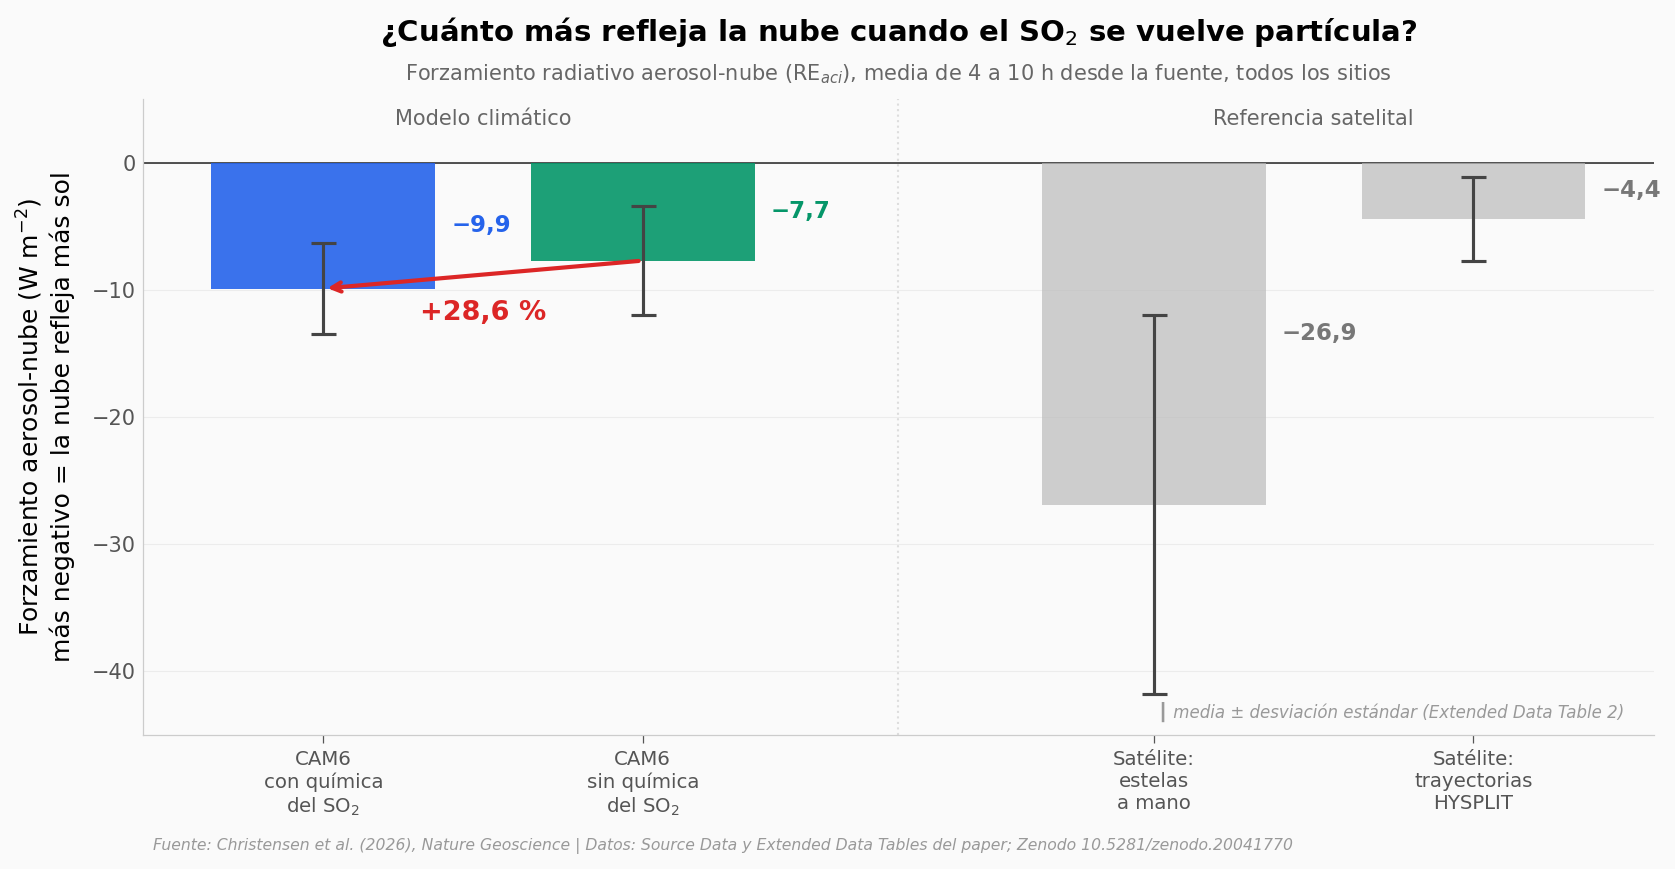

RE_aci CAM6 con química: −9,9 ± 3,6 W/m²
RE_aci CAM6 sin química: −7,7 ± 4,3 W/m²
Aumento por la química: −9,9/−7,7 = 1,286 -> +28,6 %
Solo el término Twomey (más gotas, más pequeñas): +36,0 %
Satélite: estelas a mano −26,9 ± 14,9; HYSPLIT −4,4 ± 3,3 W/m²


In [2]:
re_aci = rad[rad.termino == 're_aci_w_m2'].set_index('fuente')
twomey = rad[rad.termino == 'twomey_w_m2'].set_index('fuente')
orden = ['cam6_pluma_menos_base', 'cam6_sin_so2_menos_base', 'modis_tracks', 'modis_hysplit']
etiquetas = ['CAM6\ncon química\ndel SO$_2$', 'CAM6\nsin química\ndel SO$_2$', 'Satélite:\nestelas\na mano', 'Satélite:\ntrayectorias\nHYSPLIT']
colores = [COLOR_DATOS, COLOR_SECUNDARIO, COLOR_CONTEXTO, COLOR_CONTEXTO]
pos = [0, 1, 2.6, 3.6]

con, sin = re_aci.loc['cam6_pluma_menos_base', 'media'], re_aci.loc['cam6_sin_so2_menos_base', 'media']
aumento = 100 * (con / sin - 1)
aumento_tw = 100 * (twomey.loc['cam6_pluma_menos_base', 'media'] / twomey.loc['cam6_sin_so2_menos_base', 'media'] - 1)

fig, ax = plt.subplots(figsize=(13, 5.5))
for p, f, c in zip(pos, orden, colores):
    m, s = re_aci.loc[f, 'media'], re_aci.loc[f, 'desv_est']
    ax.bar(p, m, width=0.7, color=c, alpha=0.9 if c != COLOR_CONTEXTO else 0.7, zorder=3)
    ax.errorbar(p, m, yerr=s, fmt='none', ecolor='#444444', capsize=6, capthick=1.5, lw=1.5, zorder=4)
    ax.text(p + 0.4, m / 2, es(f'{m:.1f}'), fontsize=11, fontweight='bold', color=c if c != COLOR_CONTEXTO else '#777777', va='center')
ax.axhline(0, color='#333333', lw=0.8)
ax.annotate('', xy=(0, con), xytext=(1, sin),
            arrowprops=dict(arrowstyle='->', color=COLOR_ALERTA, lw=2))
ax.text(0.5, con - 2.5, '+' + es(f'{aumento:.1f}') + ' %', color=COLOR_ALERTA, fontsize=13, fontweight='bold', ha='center')
ax.axvline(1.8, color='#DDDDDD', lw=1, ls=':')
ax.text(0.5, 3.0, 'Modelo climático', ha='center', fontsize=10, color='#666666')
ax.text(3.1, 3.0, 'Referencia satelital', ha='center', fontsize=10, color='#666666')
ax.set_xticks(pos)
ax.set_xticklabels(etiquetas, fontsize=9.5)
ax.set_ylim(-45, 5)
ax.set_ylabel('Forzamiento aerosol-nube (W m$^{-2}$)\nmás negativo = la nube refleja más sol')
ax.set_title('¿Cuánto más refleja la nube cuando el SO$_2$ se vuelve partícula?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Forzamiento radiativo aerosol-nube (RE$_{aci}$), media de 4 a 10 h desde la fuente, todos los sitios',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.text(0.98, 0.02, '┃ media ± desviación estándar (Extended Data Table 2)', transform=ax.transAxes,
        fontsize=8, color='#999999', ha='right', va='bottom', style='italic')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/forzamiento_con_sin_quimica.png', dpi=200, bbox_inches='tight')
plt.show()

pr(f'RE_aci CAM6 con química: {con:.1f} ± {re_aci.loc["cam6_pluma_menos_base", "desv_est"]:.1f} W/m²')
pr(f'RE_aci CAM6 sin química: {sin:.1f} ± {re_aci.loc["cam6_sin_so2_menos_base", "desv_est"]:.1f} W/m²')
pr(f'Aumento por la química: {con:.1f}/{sin:.1f} = {con / sin:.3f} -> +{aumento:.1f} %')
pr(f'Solo el término Twomey (más gotas, más pequeñas): +{aumento_tw:.1f} %')
pr(f'Satélite: estelas a mano {re_aci.loc["modis_tracks", "media"]:.1f} ± {re_aci.loc["modis_tracks", "desv_est"]:.1f}; HYSPLIT {re_aci.loc["modis_hysplit", "media"]:.1f} ± {re_aci.loc["modis_hysplit", "desv_est"]:.1f} W/m²')

Con la química encendida, el modelo da un forzamiento de −9,9 W m⁻² (cuánta luz solar de más devuelve la nube al espacio: más negativo, más enfría); sin ella, −7,7 W m⁻². Ese cociente sube el enfriamiento un 28,6 %, que cuadra con el «29 %» que el abstract atribuye al albedo de las nubes; nosotros calculamos forzamiento, no albedo, y sin el cuerpo del paper no podemos confirmar que sea la misma métrica. Solo la parte de más gotas y más pequeñas (efecto Twomey) sube un 36 %.

Dos matices antes de seguir. Las barras de error de las dos corridas se solapan: la diferencia está en las medias, y la tabla no dice sobre cuántas muestras se calcula la desviación, así que no podemos saber si es distinguible estadísticamente. Y es un contraste entre simulaciones, no una medición: nadie puede apagar la química del SO₂ en una nube real.

Los dos métodos satelitales encierran al modelo por arriba y por abajo: las estelas marcadas a mano dan −26,9 W m⁻² y las trayectorias calculadas con HYSPLIT, −4,4 W m⁻².

## ¿Qué ve el satélite dentro de la estela?

Bajemos del forzamiento a algo más cercano a lo que ve el satélite: cuántas gotas tiene la nube (N_d, gotas por cm³, estimadas a partir del brillo y el tamaño de las gotas) a lo largo de la estela, frente a nubes vecinas sin contaminar.

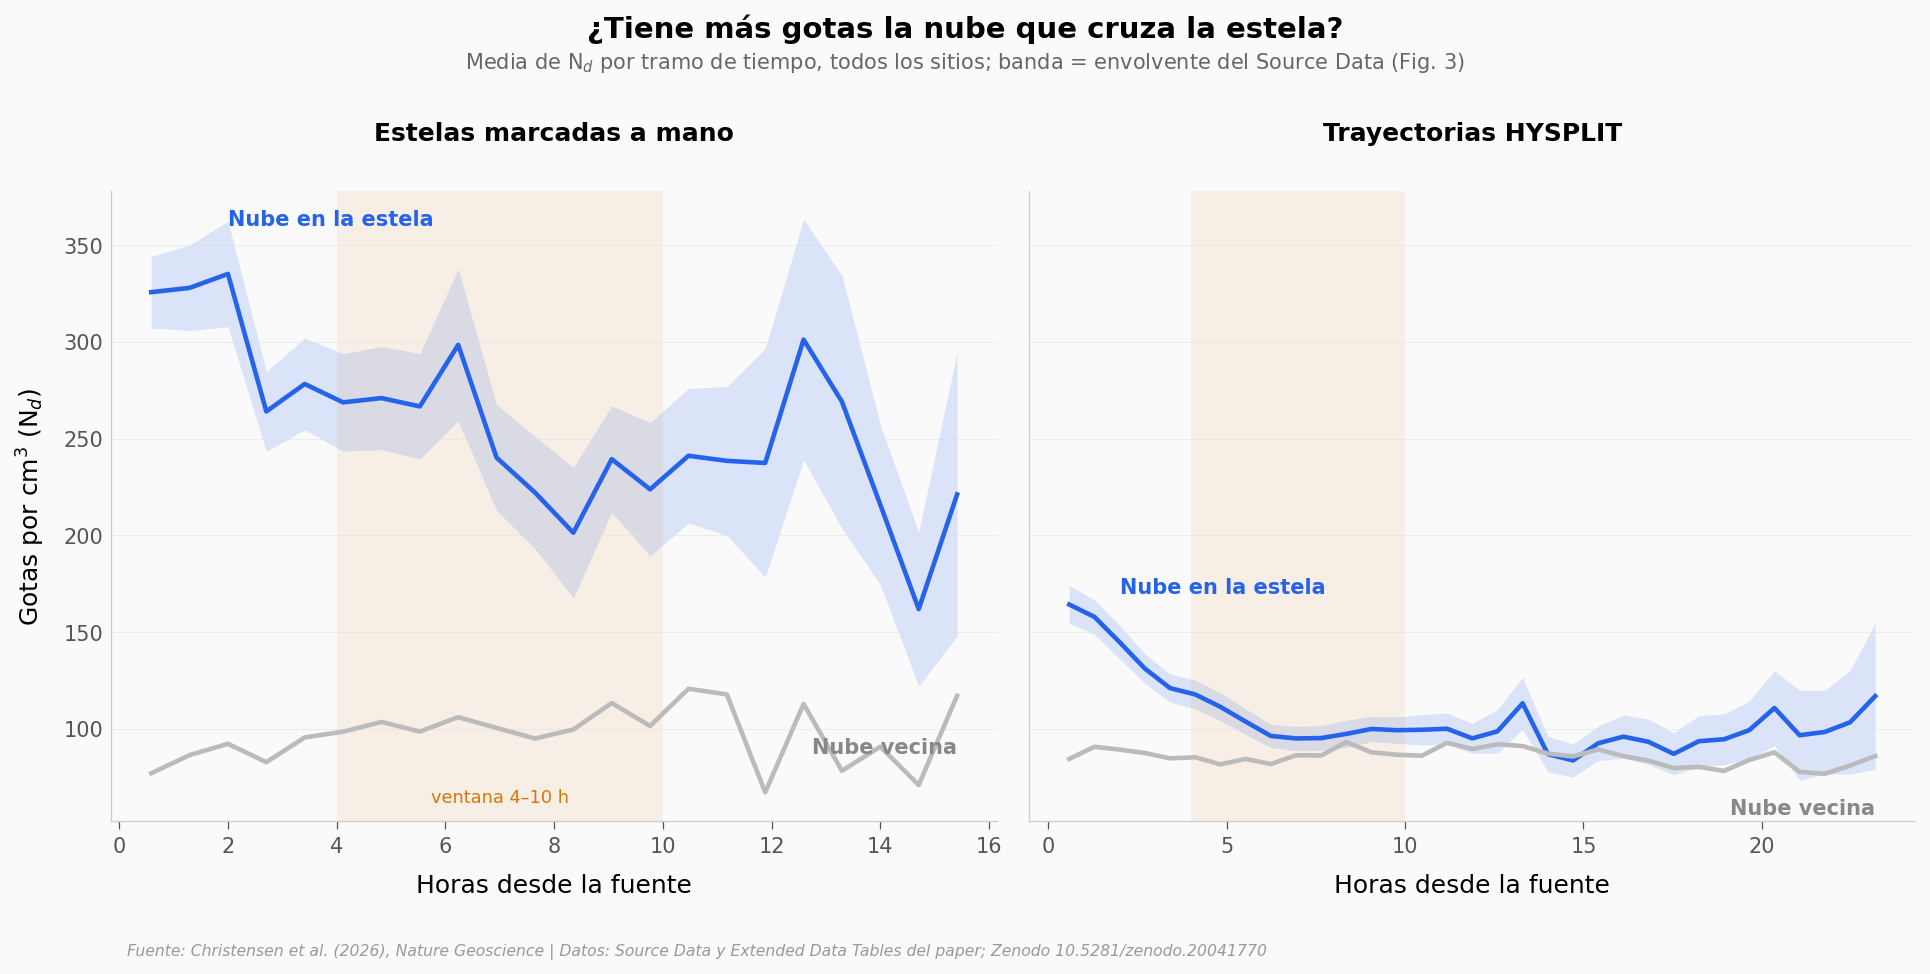

Estelas marcadas a mano: N_d en la estela > vecina en 22/22 tramos (0,6 a 15,4 h)
   primer tramo: 325,7 vs 77,0 gotas/cm³ (x4,23)
   agua líquida (LWP): estela > vecina en 17/22 tramos
Trayectorias HYSPLIT: N_d en la estela > vecina en 31/33 tramos (0,6 a 23,2 h)
   primer tramo: 164,2 vs 84,4 gotas/cm³ (x1,94)
   agua líquida (LWP): estela > vecina en 12/33 tramos


In [3]:
metodos = [('track_manual', 'Estelas marcadas a mano'), ('hysplit', 'Trayectorias HYSPLIT')]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
resumen = {}
for ax, (m, nombre) in zip(axes, metodos):
    d = sat[(sat.metodo == m) & (sat.variable == 'nd_cm3')].sort_values('tiempo_h')
    ax.fill_between(d.tiempo_h, d.contaminada_env_inf, d.contaminada_env_sup, color=COLOR_DATOS, alpha=0.15, lw=0)
    ax.plot(d.tiempo_h, d.contaminada_media, color=COLOR_DATOS, lw=2.2)
    ax.plot(d.tiempo_h, d.control_media, color=COLOR_CONTEXTO, lw=2.2)
    ax.text(d.tiempo_h.iloc[2], d.contaminada_media.iloc[2] + 25, 'Nube en la estela', color=COLOR_DATOS, fontsize=10, fontweight='bold')
    ax.text(d.tiempo_h.iloc[-1], d.control_media.iloc[-1] - 30, 'Nube vecina', color='#888888', fontsize=10, fontweight='bold', ha='right')
    ax.set_title(nombre, fontsize=12, fontweight='bold')
    ax.set_xlabel('Horas desde la fuente')
    ax.axvspan(*VENTANA_H, color=COLOR_REFERENCIA, alpha=0.08, lw=0)
    resumen[m] = d
axes[0].set_ylabel('Gotas por cm$^3$ (N$_d$)')
axes[0].text(np.mean(VENTANA_H), 0.03, 'ventana 4–10 h', ha='center', fontsize=8.5, color=COLOR_REFERENCIA, transform=axes[0].get_xaxis_transform())
plt.tight_layout()
fig.suptitle('¿Tiene más gotas la nube que cruza la estela?', fontsize=14, fontweight='bold', y=1.10)
fig.text(0.5, 1.035, 'Media de N$_d$ por tramo de tiempo, todos los sitios; banda = envolvente del Source Data (Fig. 3)',
         ha='center', fontsize=10, color='#666666')
fig.text(0.07, -0.04, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/gotas_estela_vs_control.png', dpi=200, bbox_inches='tight')
plt.show()

for m, nombre in metodos:
    d = resumen[m]
    lw = sat[(sat.metodo == m) & (sat.variable == 'lwp_g_m2')]
    mayor = int((d.contaminada_media > d.control_media).sum())
    mayor_lwp = int((lw.contaminada_media > lw.control_media).sum())
    pr(f'{nombre}: N_d en la estela > vecina en {mayor}/{len(d)} tramos (0,6 a {d.tiempo_h.max():.1f} h)')
    pr(f'   primer tramo: {d.contaminada_media.iloc[0]:.1f} vs {d.control_media.iloc[0]:.1f} gotas/cm³ (x{d.contaminada_media.iloc[0] / d.control_media.iloc[0]:.2f})')
    pr(f'   agua líquida (LWP): estela > vecina en {mayor_lwp}/{len(lw)} tramos')

Lo que llama la atención: la nube de la estela tiene más gotas en los 22 tramos de las estelas marcadas a mano, y en el primero llega a 4,23 veces las de la nube vecina. Con HYSPLIT la señal es más tenue (×1,94 al inicio) pero se sostiene en 31 de 33 tramos.

El agua líquida de la nube (LWP) es otra historia: la estela la supera en 17 de 22 tramos con estelas a mano y solo en 12 de 33 con HYSPLIT. Lo que cambia con claridad es el número de gotas, no la cantidad de agua.

## ¿Dónde entra la química?

Las gotas se forman sobre partículas llamadas núcleos de condensación de nubes (CCN). Volvamos al modelo y miremos cuántos CCN hay en la pluma de Kīlauea con y sin la química que convierte el SO₂ en sulfato.

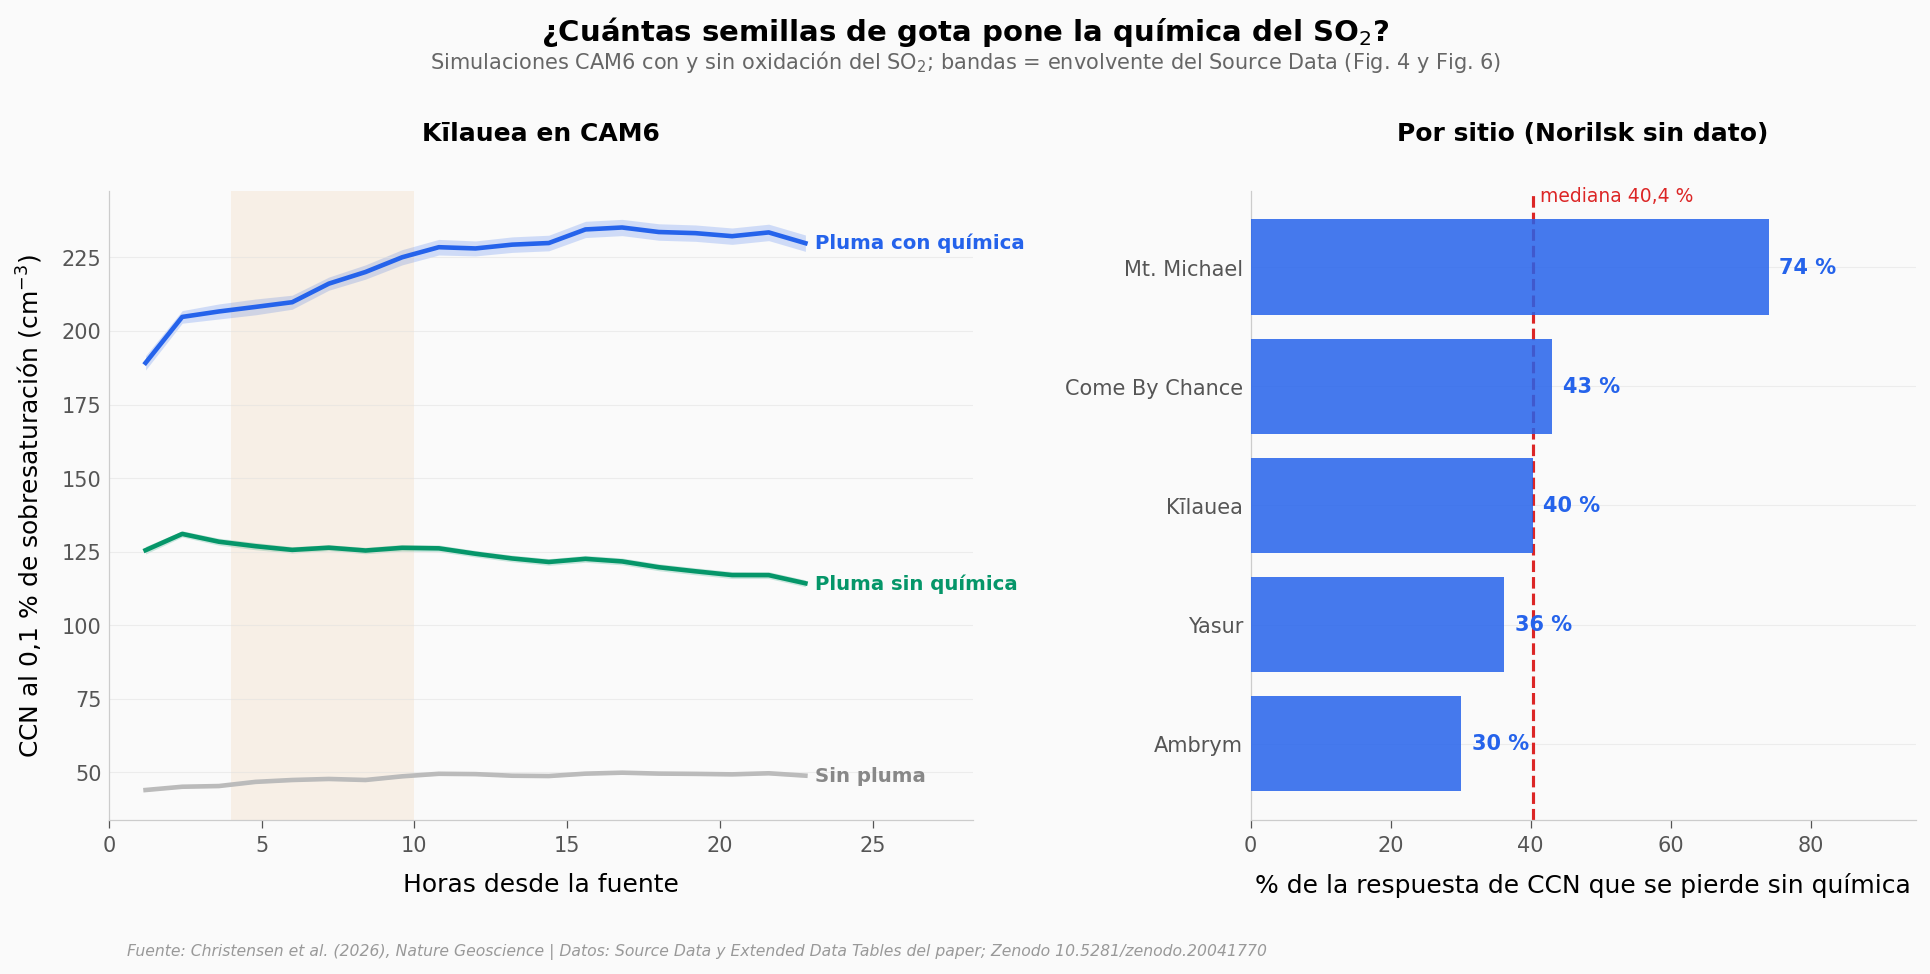

Kīlauea, ccn_01, media 4-10 h (5 puntos): sin pluma 47,6 | con química 215,8 | sin química 126,1
   la química aporta el 53,3 % del exceso sobre la línea base
  Ambrym          Δln CCN con 1,999 | sin 1,397 -> se pierde 30,1 %
  Yasur           Δln CCN con 1,232 | sin 0,786 -> se pierde 36,2 %
  Kīlauea         Δln CCN con 1,541 | sin 0,919 -> se pierde 40,4 %
  Come By Chance  Δln CCN con 0,009 | sin 0,005 -> se pierde 43,1 %
  Mt. Michael     Δln CCN con 0,394 | sin 0,102 -> se pierde 74,0 %
Mediana 40,4 % (rango 30,1-74,0 %, n = 5 sitios)


In [4]:
NOMBRES_VAR = {'ccn_01': 'CCN al 0,1 % de sobresaturación (cm$^{-3}$)', 'nd': 'Gotas por cm$^3$ (N$_d$)',
               'so4': 'Sulfato (µg m$^{-3}$)', 'lwp': 'Agua líquida (g m$^{-2}$)',
               'albedo_nube': 'Albedo de la nube', 'so2': 'SO$_2$ (ppb)'}
ESC = [('linea_base', 'Sin pluma', COLOR_CONTEXTO), ('base_mas_pluma', 'Pluma con química', COLOR_DATOS),
       ('pluma_sin_so2', 'Pluma sin química', COLOR_SECUNDARIO)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
k = kil[kil.variable == VARIABLE_KIL]
medias = {}
for e, nombre, c in ESC:
    d = k[k.escenario == e].sort_values('tiempo_h')
    ax.fill_between(d.tiempo_h, d.envolvente_inf, d.envolvente_sup, color=c, alpha=0.2, lw=0)
    ax.plot(d.tiempo_h, d.media, color=c, lw=2.2)
    ax.text(d.tiempo_h.iloc[-1] + 0.3, d.media.iloc[-1], nombre, color=c if c != COLOR_CONTEXTO else '#888888',
            fontsize=9.5, fontweight='bold', va='center')
    v = d[(d.tiempo_h >= VENTANA_H[0]) & (d.tiempo_h <= VENTANA_H[1])]
    medias[e] = (v.media.mean(), len(v))
ax.axvspan(*VENTANA_H, color=COLOR_REFERENCIA, alpha=0.08, lw=0)
ax.set_xlim(0, k.tiempo_h.max() + 5.5)
ax.set_xlabel('Horas desde la fuente')
ax.set_ylabel(NOMBRES_VAR[VARIABLE_KIL])
ax.set_title('Kīlauea en CAM6', fontsize=12, fontweight='bold')

# Fracción de la respuesta de CCN que desaparece sin química, por sitio (métrica didáctica:
# 1 - Δln CCN(sin química) / Δln CCN(con química), media 4-10 h de CAM6)
ax = axes[1]
c_con = dln[(dln.variable == 'CCN') & (dln.fuente == 'CAM6 plume-baseline')].set_index('codigo')
c_sin = dln[(dln.variable == 'CCN') & (dln.fuente == 'CAM6 plume-noSO2-baseline')].set_index('codigo')
frac = (1 - c_sin.delta_ln / c_con.delta_ln) * 100
frac[c_sin.delta_ln == 0] = np.nan   # Norilsk: el Source Data no trae la corrida sin química
frac = frac.dropna().sort_values()
nombres = c_con.loc[frac.index, 'sitio'].str.replace('Come-by-Chance', 'Come By Chance')
ax.barh(range(len(frac)), frac.values, color=COLOR_DATOS, alpha=0.85, zorder=3)
for i, v in enumerate(frac.values):
    ax.text(v + 1.5, i, es(f'{v:.0f} %'), va='center', fontsize=10, color=COLOR_DATOS, fontweight='bold')
ax.axvline(frac.median(), color=COLOR_ALERTA, lw=1.5, ls='--')
ax.text(frac.median() + 1, len(frac) - 0.45, 'mediana ' + es(f'{frac.median():.1f} %'), color=COLOR_ALERTA, fontsize=9)
ax.set_yticks(range(len(frac)))
ax.set_yticklabels(nombres, fontsize=10)
ax.set_xlim(0, 95)
ax.set_xlabel('% de la respuesta de CCN que se pierde sin química')
ax.set_title('Por sitio (Norilsk sin dato)', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.suptitle('¿Cuántas semillas de gota pone la química del SO$_2$?', fontsize=14, fontweight='bold', y=1.10)
fig.text(0.5, 1.035, 'Simulaciones CAM6 con y sin oxidación del SO$_2$; bandas = envolvente del Source Data (Fig. 4 y Fig. 6)',
         ha='center', fontsize=10, color='#666666')
fig.text(0.07, -0.04, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/ccn_con_sin_quimica.png', dpi=200, bbox_inches='tight')
plt.show()

b, p_, s_ = medias['linea_base'][0], medias['base_mas_pluma'][0], medias['pluma_sin_so2'][0]
pr(f'Kīlauea, {VARIABLE_KIL}, media {VENTANA_H[0]}-{VENTANA_H[1]} h ({medias["linea_base"][1]} puntos): sin pluma {b:.3g} | con química {p_:.4g} | sin química {s_:.4g}')
pr(f'   la química aporta el {100 * (p_ - s_) / (p_ - b):.1f} % del exceso sobre la línea base')
for cod in frac.index:
    pr(f'  {nombres[cod]:<15} Δln CCN con {c_con.loc[cod, "delta_ln"]:.3f} | sin {c_sin.loc[cod, "delta_ln"]:.3f} -> se pierde {frac[cod]:.1f} %')
pr(f'Mediana {frac.median():.1f} % (rango {frac.min():.1f}-{frac.max():.1f} %, n = {len(frac)} sitios)')

En Kīlauea, entre las 4 y las 10 horas, la química aporta el 53,3 % de los CCN extra que trae la pluma. Sitio por sitio, apagarla borra entre el 30 % y el 74 % de la respuesta de CCN, con una mediana de 40,4 % en los cinco sitios con las dos corridas. Mt. Michael, el volcán que menos SO₂ emite, es el que más depende de la química. El 43 % de Come By Chance es frágil: su respuesta de CCN es casi nula en las dos corridas (Δln de 0,009 y 0,005).

## ¿Cómo crece una partícula hasta volverse semilla?

El sulfato recién formado son partículas diminutas. Para el último paso el equipo usó una simulación de caja (PartMC): un volumen de aire aislado donde se sigue partícula por partícula. Simularon un soplo de la pluma de Kīlauea con 100 ppb de SO₂ durante 24 horas, apagando por turnos la formación de partículas nuevas o la coagulación (partículas que chocan y se pegan).

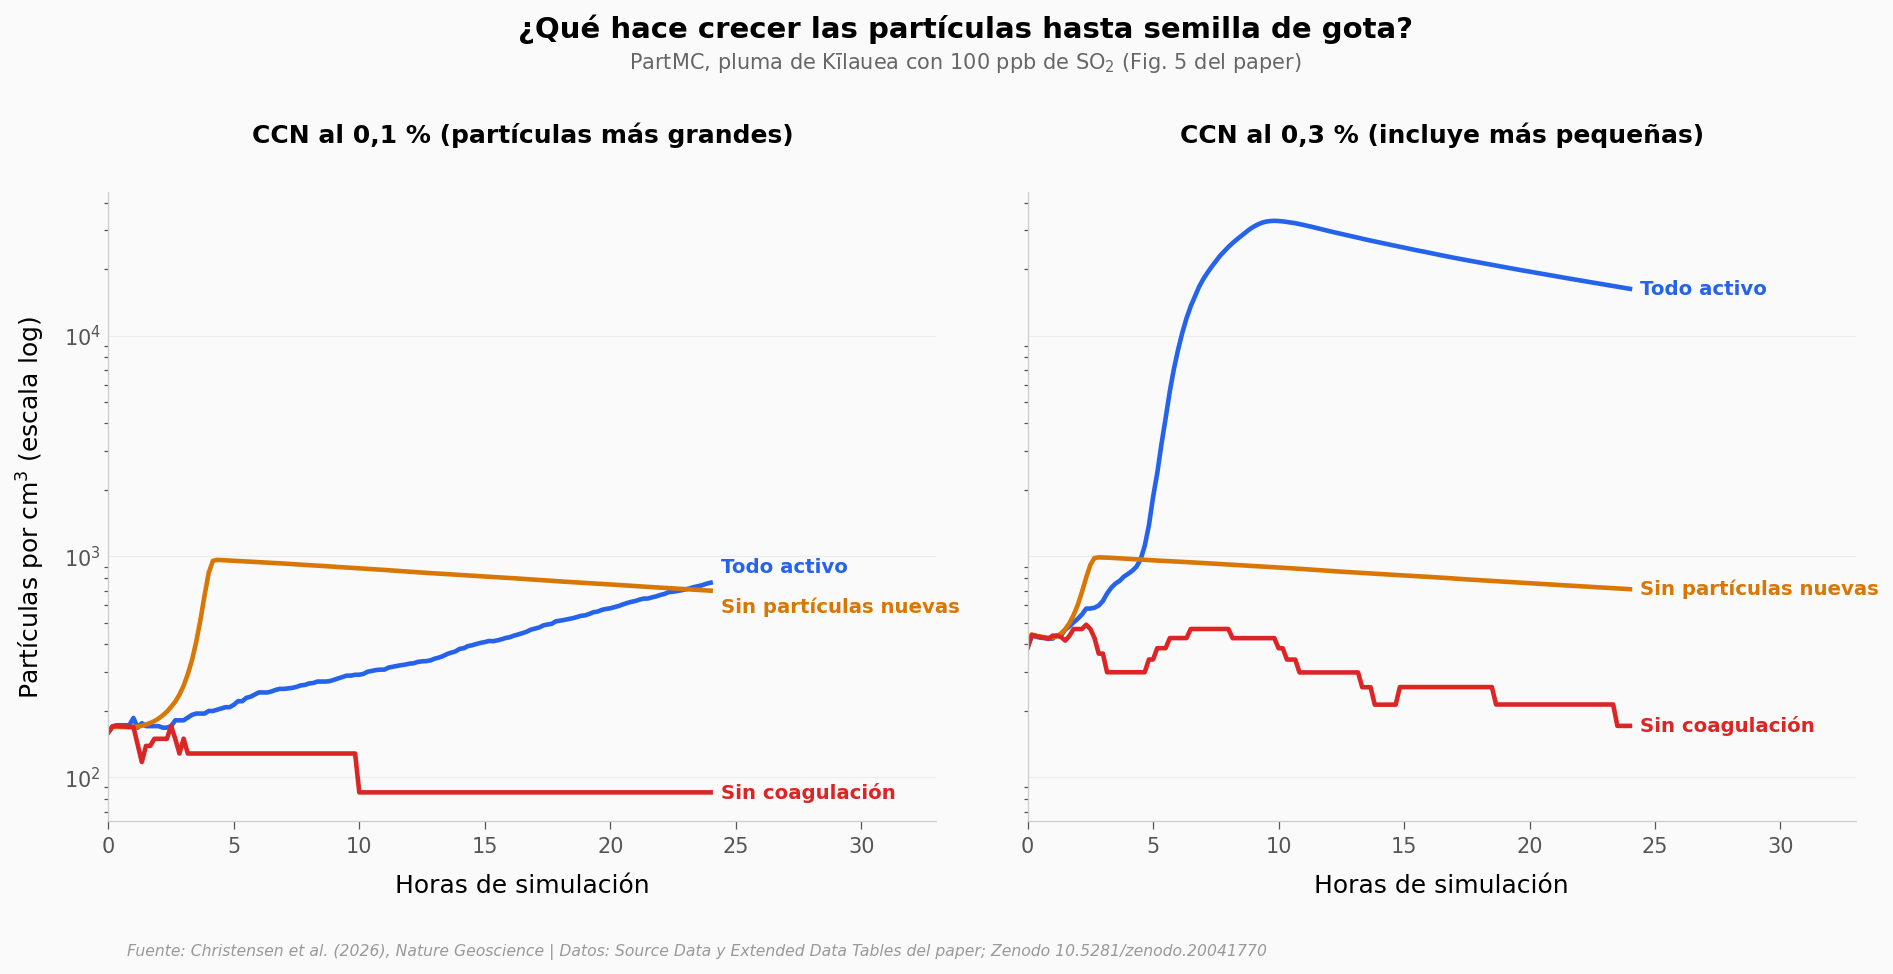

ccn_01_cm3 a las 24 h: Todo activo 760,4 | Sin partículas nuevas 699,7 | Sin coagulación 85,5
ccn_03_cm3 a las 24 h: Todo activo 16.268,8 | Sin partículas nuevas 710,9 | Sin coagulación 170,9
n_total_cm3 a las 24 h: Todo activo 17.242,5 | Sin partículas nuevas 725,3 | Sin coagulación 2.106.583,1
CCN 0,1 %: todo activo / sin coagulación = x8,9
CCN 0,1 % sin coagulación: 159,7 al inicio -> 85,5 a las 24 h
CCN 0,1 %: "sin partículas nuevas" supera a "todo activo" en 131 de 145 pasos
Número total a las 24 h: sin coagulación / todo activo = x122
SO₂: 100 -> 60,4 ppb en 24 h


In [5]:
ESC_P = [('todo_activo', 'Todo activo', COLOR_DATOS), ('sin_npf', 'Sin partículas nuevas', COLOR_REFERENCIA),
         ('sin_coagulacion', 'Sin coagulación', COLOR_ALERTA)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, col, nombre in zip(axes, ['ccn_01_cm3', 'ccn_03_cm3'], ['CCN al 0,1 % (partículas más grandes)', 'CCN al 0,3 % (incluye más pequeñas)']):
    for e, lab, c in ESC_P:
        d = pmc[pmc.escenario == e].sort_values('tiempo_h')
        ax.plot(d.tiempo_h, d[col], color=c, lw=2.2)
        desp = {'todo_activo': 1.18, 'sin_npf': 0.85}.get(e, 1.0) if col == 'ccn_01_cm3' else 1.0
        ax.text(24.4, d[col].iloc[-1] * desp, lab, color=c, fontsize=9.5, fontweight='bold', va='center')
    ax.set_yscale('log')
    ax.set_xlim(0, 33)
    ax.set_xlabel('Horas de simulación')
    ax.set_title(nombre, fontsize=12, fontweight='bold')
axes[0].set_ylabel('Partículas por cm$^3$ (escala log)')
plt.tight_layout()
fig.suptitle('¿Qué hace crecer las partículas hasta semilla de gota?', fontsize=14, fontweight='bold', y=1.10)
fig.text(0.5, 1.035, 'PartMC, pluma de Kīlauea con 100 ppb de SO$_2$ (Fig. 5 del paper)', ha='center', fontsize=10, color='#666666')
fig.text(0.07, -0.04, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/partmc_coagulacion.png', dpi=200, bbox_inches='tight')
plt.show()

fin = pmc[pmc.tiempo_h == pmc.tiempo_h.max()].set_index('escenario')
ini = pmc[pmc.tiempo_h == 0].set_index('escenario')
for col in ['ccn_01_cm3', 'ccn_03_cm3', 'n_total_cm3']:
    pr(f'{col} a las 24 h: ' + ' | '.join(f'{lab} {fin.loc[e, col]:_.1f}' for e, lab, _ in ESC_P))
pr(f'CCN 0,1 %: todo activo / sin coagulación = x{fin.loc["todo_activo", "ccn_01_cm3"] / fin.loc["sin_coagulacion", "ccn_01_cm3"]:.1f}')
pr(f'CCN 0,1 % sin coagulación: {ini.loc["sin_coagulacion", "ccn_01_cm3"]:.1f} al inicio -> {fin.loc["sin_coagulacion", "ccn_01_cm3"]:.1f} a las 24 h')
ta = pmc[pmc.escenario == 'todo_activo'].set_index('tiempo_h').ccn_01_cm3
sn = pmc[pmc.escenario == 'sin_npf'].set_index('tiempo_h').ccn_01_cm3
pr(f'CCN 0,1 %: "sin partículas nuevas" supera a "todo activo" en {(sn > ta).sum()} de {len(ta)} pasos')
pr(f'Número total a las 24 h: sin coagulación / todo activo = x{fin.loc["sin_coagulacion", "n_total_cm3"] / fin.loc["todo_activo", "n_total_cm3"]:.0f}')
pr(f'SO₂: {ini.loc["todo_activo", "so2_ppb"]:.0f} -> {fin.loc["todo_activo", "so2_ppb"]:.1f} ppb en 24 h')

Sin coagulación, el aire se llena de partículas diminutas (2,11 millones por cm³ a las 24 horas) pero casi ninguna llega a semilla: los CCN al 0,1 % caen de 159,7 a 85,5 por cm³, y con todo activo hay 8,9 veces más. Es lo que el abstract plantea con cautela: los cálculos sugieren que la coagulación domina el crecimiento hasta tamaño de semilla.

Ojo con la formación de partículas nuevas: para los CCN al 0,1 %, apagarla casi no cambia el resultado final (699,7 frente a 760,4 por cm³ a las 24 h), pero por el camino sí: sin partículas nuevas hay más CCN al 0,1 % que con todo activo en 131 de 145 pasos, y las curvas solo se juntan al final. A las 24 h su peso aparece en los CCN al 0,3 %, que incluyen partículas más pequeñas (16.268,8 frente a 710,9 por cm³).

## ¿Qué tan fino es el rastreo?

Una de las dos referencias satelitales no marca la estela a mano: la reconstruye con trayectorias del viento (HYSPLIT). ¿Cuánto se equivoca esa trayectoria frente a la estela que se ve en la imagen?

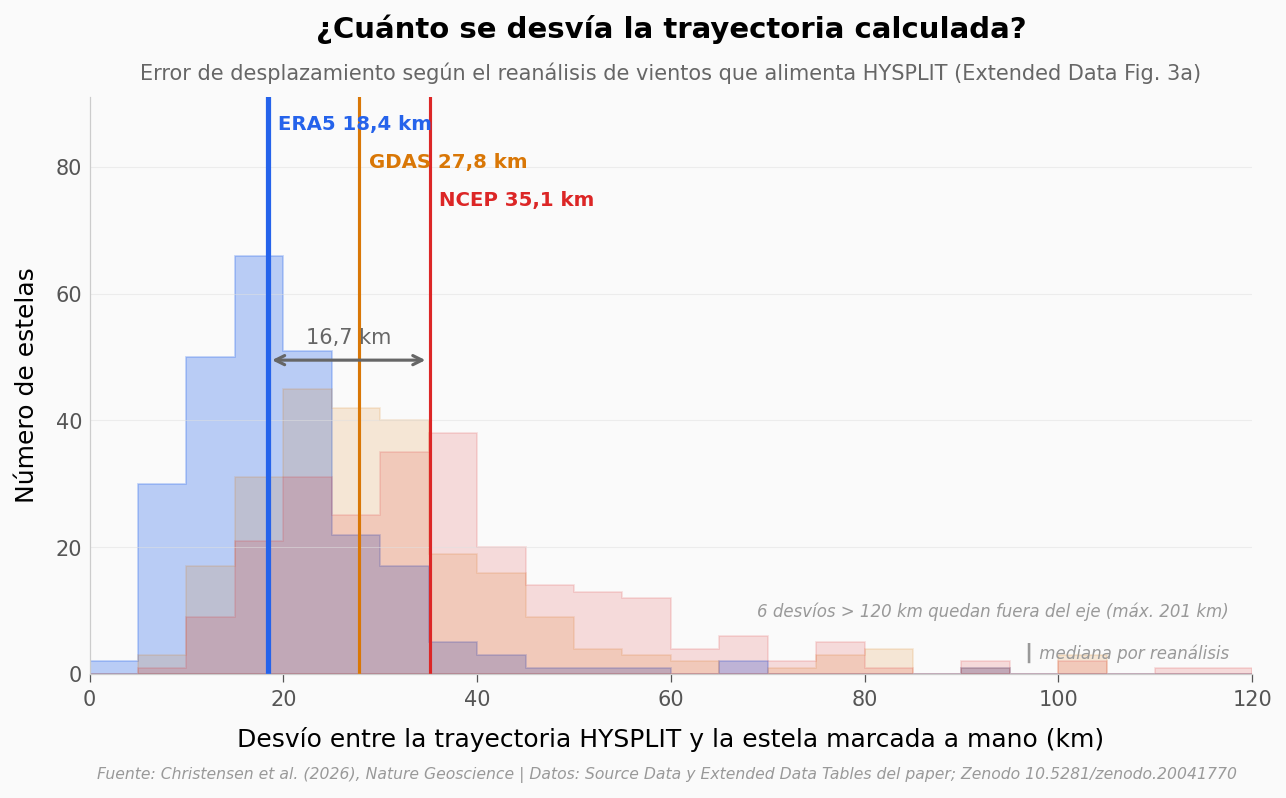

ERA5: n = 252 | mediana 18,4 km (IQR 13,1-23,9) | media 20,0 | asimetría 2,40
GDAS: n = 245 | mediana 27,8 km (IQR 21,3-36,5) | media 32,3 | asimetría 3,01
NCEP: n = 247 | mediana 35,1 km (IQR 24,9-46,6) | media 39,8 | asimetría 2,88


In [6]:
COL_R = {'ERA5': COLOR_DATOS, 'GDAS': COLOR_REFERENCIA, 'NCEP': COLOR_ALERTA}
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(0, err.error_desplazamiento_km.max() + 5, 5)
y_max = 0
med = {}
for r in ['ERA5', 'GDAS', 'NCEP']:
    v = err[err.reanalisis == r].error_desplazamiento_km
    n, _, _ = ax.hist(v, bins=bins, color=COL_R[r], alpha=0.30 if r == REANALISIS_REF else 0.15,
                      edgecolor=COL_R[r], linewidth=0.8, histtype='stepfilled')
    y_max = max(y_max, n.max())
    med[r] = v.median()
ax.set_ylim(0, y_max * 1.38)
for r, h in zip(['ERA5', 'GDAS', 'NCEP'], [1.30, 1.21, 1.12]):
    ax.axvline(med[r], color=COL_R[r], lw=2.5 if r == REANALISIS_REF else 1.5)
    ax.text(med[r] + 1, y_max * h, r + ' ' + es(f'{med[r]:.1f} km'), color=COL_R[r], fontsize=9.5, fontweight='bold')
otro = max(med, key=med.get) if REANALISIS_REF != max(med, key=med.get) else min(med, key=med.get)
ax.annotate('', xy=(med[otro], y_max * 0.75), xytext=(med[REANALISIS_REF], y_max * 0.75),
            arrowprops=dict(arrowstyle='<->', color='#666666', lw=1.5))
ax.text((med[otro] + med[REANALISIS_REF]) / 2, y_max * 0.79, es(f'{abs(med[otro] - med[REANALISIS_REF]):.1f} km'),
        ha='center', fontsize=10, color='#666666')
ax.set_xlim(0, 120)
fuera = int((err.error_desplazamiento_km > 120).sum())
ax.text(0.98, 0.10, f'{fuera} desvíos > 120 km quedan fuera del eje (máx. ' + es(f'{err.error_desplazamiento_km.max():.0f} km)'),
        transform=ax.transAxes, fontsize=8, color='#999999', ha='right', style='italic')
ax.set_xlabel('Desvío entre la trayectoria HYSPLIT y la estela marcada a mano (km)')
ax.set_ylabel('Número de estelas')
ax.set_title('¿Cuánto se desvía la trayectoria calculada?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Error de desplazamiento según el reanálisis de vientos que alimenta HYSPLIT (Extended Data Fig. 3a)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
ax.text(0.98, 0.02, '┃ mediana por reanálisis', transform=ax.transAxes, fontsize=8, color='#999999', ha='right', va='bottom', style='italic')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/error_hysplit.png', dpi=200, bbox_inches='tight')
plt.show()

for r in ['ERA5', 'GDAS', 'NCEP']:
    v = err[err.reanalisis == r].error_desplazamiento_km
    q1, q3 = v.quantile([0.25, 0.75])
    pr(f'{r}: n = {len(v)} | mediana {v.median():.1f} km (IQR {q1:.1f}-{q3:.1f}) | media {v.mean():.1f} | asimetría {stats.skew(v):.2f}')

Con los vientos de ERA5, la trayectoria calculada cae a una mediana de 18,4 km de la estela real; con NCEP, a 35,1 km. Las tres distribuciones tienen cola larga a la derecha, así que la mediana describe mejor el caso típico que la media. Un desvío de decenas de kilómetros es una explicación posible de por qué HYSPLIT ve una señal más tenue (Δln N_d de 0,33 frente a 1,11 con estelas a mano), pero este notebook no lo pone a prueba.

### Lo que los datos soportan

| Afirmación | ¿Soportada? | Detalle |
|------------|-------------|---------|
| En CAM6 el forzamiento aerosol-nube es 28,6 % mayor con la química del SO₂ | ⚠️ | Cociente de la Extended Data Table 2: −9,9 ± 3,6 frente a −7,7 ± 4,3 W m⁻². Cuadra con el «29 %» del abstract, que lo llama albedo; el cuerpo del paper está tras muro de pago y no podemos confirmar qué métrica exacta usa. Las desviaciones se solapan. |
| La nube dentro de la estela tiene más gotas que la nube vecina | ✅ | 22 de 22 tramos con estelas a mano y 31 de 33 con HYSPLIT; ×4,23 en el primer tramo con estelas a mano. |
| El número de gotas responde mucho más que el agua líquida | ✅ | Agua líquida mayor en la estela en 17 de 22 tramos (a mano) y 12 de 33 (HYSPLIT). En la Extended Data Table 2, Δln LWP de CAM6 = 0,16 frente a Δln N_d = 0,94. |
| CAM6 coincide con el satélite dentro de la incertidumbre | ⚠️ | En forzamiento, CAM6 (−9,9 ± 3,6) se solapa con estelas a mano (−26,9 ± 14,9) y con HYSPLIT (−4,4 ± 3,3). En gotas, se solapa con estelas a mano (0,94 ± 0,28 frente a 1,11 ± 0,18) pero no con HYSPLIT (0,33 ± 0,10). |
| En CAM6, sin la química se pierde entre el 30 % y el 74 % de la respuesta de CCN | ✅ | CAM6, 5 sitios, mediana 40,4 %. Norilsk queda fuera porque el Source Data no trae su corrida sin química. Métrica didáctica nuestra (cociente de Δln), no del paper. |
| En PartMC, sin coagulación hay 8,9 veces menos CCN al 0,1 % | ✅ | 85,5 frente a 760,4 por cm³ a las 24 h. Un solo escenario: Kīlauea, 100 ppb de SO₂. Respalda lo que el abstract sugiere sobre la coagulación. |
| Con 6 sitios no se detecta relación entre el SO₂ emitido y la frecuencia de estelas | ⚠️ | Spearman ρ = −0,12 (p = 0,83). Con n = 6 esto no prueba que la relación no exista. |
| Menos emisiones de SO₂ podrían acelerar el calentamiento | ❌ | No es que la contradigan: los datos de este notebook no la evalúan. Es la proyección del paper (*possibly accelerating*). |

> **Limitaciones:** el 29 % y todo el bloque «con y sin química» salen de simulaciones (CAM6 y PartMC), no de observaciones. Las bandas de las Fig. 3 y 4 son envolventes del Source Data, sin poder confirmar si son desviación estándar o error estándar. Las Extended Data Tables se transcribieron de imagen. Las emisiones de SO₂ de la Extended Data Table 1 y las del catálogo satelital de la Extended Data Fig. 1 difieren hasta 1,9 veces en tres volcanes: aquí usamos las de la tabla. Seis sitios es una muestra pequeña para cualquier comparación entre ellos.

## Ahora tú

1. **¿Los volcanes que más SO₂ emiten dejan más estelas?** La celda de abajo cruza las emisiones de la Extended Data Table 1 con la frecuencia de estelas por sitio. Pista: fíjate en Mt. Michael.
2. **¿La química pesa igual en las gotas que en los CCN?** Cambia `VARIABLE_KIL = 'nd'` (o `'albedo_nube'`) en la celda de configuración y vuelve a correr la gráfica de Kīlauea: mira qué fracción del exceso aporta la química.
3. **¿Cambia mucho el desvío según los vientos?** Pon `REANALISIS_REF = 'NCEP'` y compara la flecha del histograma.

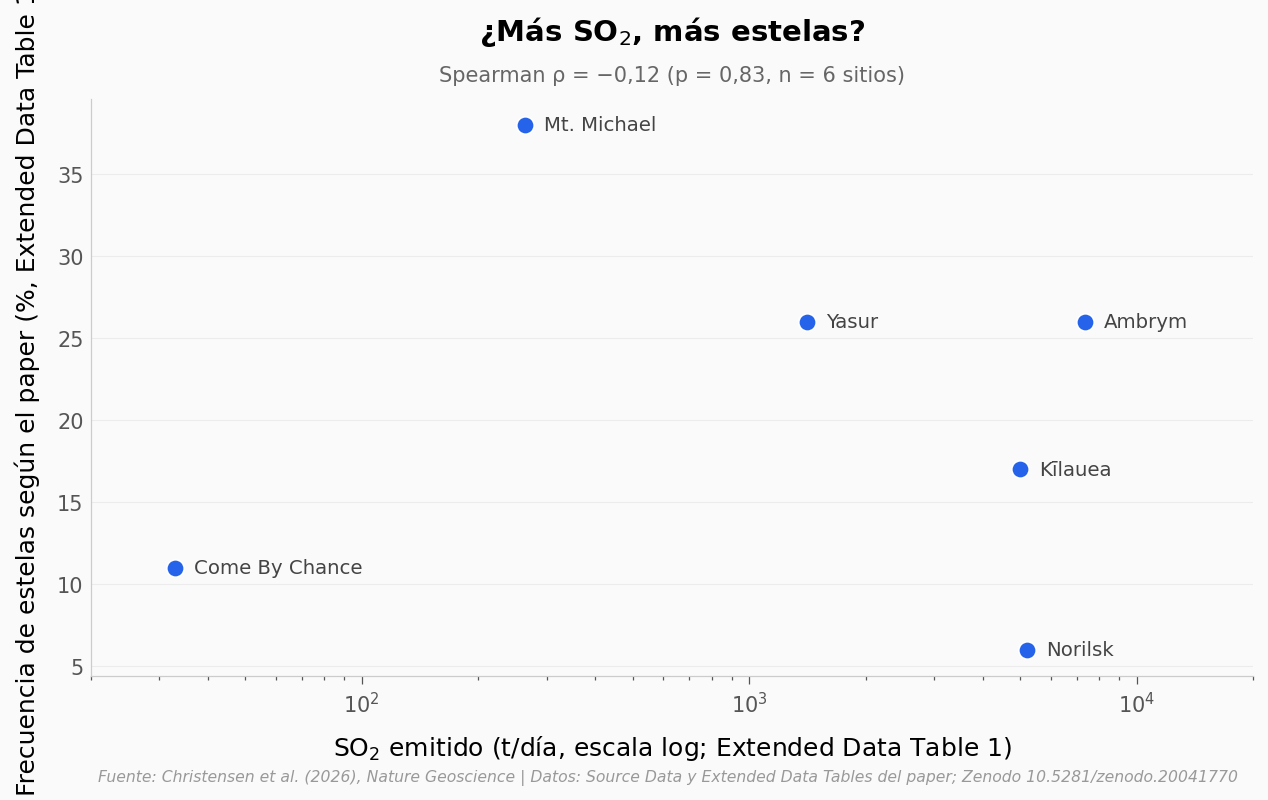

Spearman ρ = −0,12, p = 0,83, n = 6
Frecuencia según el paper vs nuestra (estelas / gránulos totales):
  Mt. Michael      38 % | 27,7 %
  Ambrym           26 % | 20,5 %
  Yasur            26 % | 20,6 %
  Kīlauea          17 % | 14,4 %
  Come By Chance   11 % | 10,0 %
  Norilsk           6 % | 5,5 %


In [7]:
# --- EXPERIMENTA AQUÍ ---
# ¿Más SO2 emitido, más estelas? (Spearman: n = 6, solo descriptivo)
s = sitios.copy()
s['frecuencia_lab_pct'] = 100 * s.n_granulos_con_track / s.n_granulos_total
# Ojo: la frecuencia del paper se reproduce como estelas / gránulos SIN estela (Mt. Michael: 94/245 = 38 %),
# no sobre el total; abajo imprimimos las dos para que compares.
rho, p = stats.spearmanr(s.so2_t_dia_paper, s.frecuencia_pct_paper)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(s.so2_t_dia_paper, s.frecuencia_pct_paper, color=COLOR_DATOS, s=70, edgecolors='white', linewidths=0.8, zorder=5)
for _, r in s.iterrows():
    ax.text(r.so2_t_dia_paper * 1.12, r.frecuencia_pct_paper, r.sitio, fontsize=9.5, va='center', color='#444444')
ax.set_xscale('log')
ax.set_xlim(20, 20000)
ax.set_xlabel('SO$_2$ emitido (t/día, escala log; Extended Data Table 1)')
ax.set_ylabel('Frecuencia de estelas según el paper (%, Extended Data Table 1)')
ax.set_title('¿Más SO$_2$, más estelas?', fontsize=14, fontweight='bold', pad=28)
ax.text(0.5, 1.03, 'Spearman ρ = ' + es(f'{rho:.2f}') + ' (p = ' + es(f'{p:.2f}') + ', n = 6 sitios)',
        transform=ax.transAxes, fontsize=10, color='#666666', ha='center')
fig.text(0.13, -0.03, FUENTE, fontsize=7.5, color='#999999', style='italic')
plt.savefig('figuras/so2_vs_frecuencia.png', dpi=200, bbox_inches='tight')
plt.show()
pr(f'Spearman ρ = {rho:.2f}, p = {p:.2f}, n = {len(s)}')
pr('Frecuencia según el paper vs nuestra (estelas / gránulos totales):')
for _, r in s.sort_values('frecuencia_pct_paper', ascending=False).iterrows():
    pr(f'  {r.sitio:<15} {r.frecuencia_pct_paper:>3} % | {r.frecuencia_lab_pct:.1f} %')

## Créditos

- **Paper:** Christensen et al. (2026). *Chemical processing of sulfur dioxide enhances cloud sensitivity to aerosols*. Nature Geoscience. [DOI: 10.1038/s41561-026-02140-9](https://doi.org/10.1038/s41561-026-02140-9)
- **Datos:** Source Data y Extended Data Tables del paper; conteos de gránulos del depósito en Zenodo ([10.5281/zenodo.20041770](https://doi.org/10.5281/zenodo.20041770)).
- **Notebook:** [Ciencia a Mordiscos — El Lab](https://github.com/Ciencia-a-Mordiscos/lab) · licencia del repositorio.

## Fuentes

**Paper**: [Chemical processing of sulfur dioxide enhances cloud sensitivity to aerosols](https://doi.org/10.1038/s41561-026-02140-9)  
*Nature Geoscience, 2026-11-27 · paywall*

**Supplementary Material**: [Source Data (Figs. 2–6, Extended Data Figs. 1–8) for Chemical processing of sulfur dioxide enhances cloud sensitivity to aerosols](https://www.nature.com/articles/s41561-026-02140-9#Sec-source-data)  
*Nature Geoscience, 2026-11-27*

**Supplementary Material**: [Extended Data Tables 1–2 for Chemical processing of sulfur dioxide enhances cloud sensitivity to aerosols](https://www.nature.com/articles/s41561-026-02140-9/tables/2)  
*Nature Geoscience, 2026-11-27*

**Datos**: [Pollution Tracks in Lagrangian Framework Dataset](https://doi.org/10.5281/zenodo.20041770)  
*Zenodo, 2026-05-05: conteos de gránulos MODIS con y sin estela*

**Referencias citadas**: [Version 2 of the global catalogue of large anthropogenic and volcanic SO2 sources and emissions derived from satellite measurements (Fioletov et al., 2023)](https://doi.org/10.5194/essd-15-75-2023)

*19 afirmaciones del notebook verificadas contra estas fuentes*